# Modèles d'arbres et ensembles

Le sujet, les données et leur preprocessing, les protocoles et les métriques sont présentés dans `introduction.ipynb`.

## 1. Pourquoi les arbres de décision ?

Dans le notebook [`regression_lineaire.ipynb`], nous avons poussé la régression linéaire dans ses derniers retranchements :
- Pour capturer les pics horaires (8h et 18h en semaine, bosse continue le week-end) et les effets de seuil météo (chute brutale de la demande sous $0^\circ\text{C}$ ou en cas d'averse), il a fallu créer **plus de 4 000 variables polynomiales de degré 2** et régulariser avec Ridge ($\alpha=1000$).
- Ce modèle linéaire atteignait $\text{RMSE CV} = 204.4$ vélos/h en Daily et $363.9$ vélos/h en Temporal.

Les **modèles d'arbres de décision et leurs ensembles (Random Forest, Gradient Boosting, LightGBM, XGBoost)** changent fondamentalement de paradigme :
1. **Non-linéarités naturelles sans feature engineering complexe** : les arbres découpent l'espace par partitions orthogonales successives ($x_j \le s$), apprenant automatiquement les seuils thermiques ou horaires sans nécessiter de puissances ou de polynômes.
2. **Interactions d'ordre supérieur automatiques** : un chemin dans l'arbre modélise directement une règle conditionnelle (*"SI heure = 18h ET jour ouvré ET pluie > 1mm ALORS..."*).
3. **Invariance d'échelle** : les arbres étant basés sur des comparaisons d'ordre, aucune normalisation (*scaling*) préalable n'est requise.

### Protocoles
Chaque modèle est évalué avec les deux protocoles communs de `decoupage.py` :
- **Daily** : 283 jours d'entraînement et 70 jours de test répartis sur les 12 mois ; cross-validation à 5 plis (`cv_daily`).
- **Temporal** : entraînement du 01/12/2017 au 10/09/2018 (282 jours) et test sur les 10 semaines suivantes (11/09 au 30/11/2018) ; cross-validation sur 23 semaines successives (`cv_temporal`).

Comme dans les autres notebooks, les réglages sont choisis sur la cross-validation daily ; le temporal sert à vérifier si les modèles tiennent sur le futur.

## 2. Import des bibliothèques et des données

Nous importons les données via `decoupage.py`, commun à toute l'équipe.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

# Scikit-Learn : Arbres, Bagging, Boosting
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)
from sklearn.model_selection import cross_validate
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

# XGBoost & LightGBM
try:
    import xgboost as xgb
    HAS_XGB = True
    print(f"XGBoost chargé avec succès (version {xgb.__version__}) !")
except Exception as e:
    HAS_XGB = False
    print(f"ℹ XGBoost non disponible : {e}")

try:
    import lightgbm as lgb
    HAS_LGBM = True
    print(f"LightGBM chargé avec succès (version {lgb.__version__}) !")
except ImportError:
    HAS_LGBM = False
    print("ℹ LightGBM non installé -> utilisation de HistGradientBoostingRegressor (même algorithme)")

# Import du module commun de découpage
from decoupage import charger_donnees, decoupage_daily, cv_daily, decoupage_temporal, cv_temporal, walk_forward, variables, CIBLE

# Configuration graphique globale
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

df_brut = charger_donnees()

# 1. Protocole DAILY (stratifié par mois)
train, test = decoupage_daily(df_brut)
TARGET = CIBLE
FEATURES = variables(train)
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

# 2. Protocole TEMPORAL (extrapolation séquentielle)
train_temporal, test_temporal = decoupage_temporal(df_brut)
X_train_temporal, y_train_temporal = train_temporal[FEATURES], train_temporal[TARGET]
X_test_temporal, y_test_temporal = test_temporal[FEATURES], test_temporal[TARGET]

print(f"DAILY    : Train {train['date'].nunique()} jours ({X_train.shape[0]}h) | Test {test['date'].nunique()} jours ({X_test.shape[0]}h)")
print(f"TEMPORAL : Train {train_temporal['date'].nunique()} jours ({X_train_temporal.shape[0]}h) | Test 10 semaines ({X_test_temporal.shape[0]}h)")


XGBoost chargé avec succès (version 3.4.1) !
LightGBM chargé avec succès (version 4.7.0) !
DAILY    : Train 283 jours (6785h) | Test 70 jours (1680h)
TEMPORAL : Train 282 jours (6768h) | Test 10 semaines (1697h)


## 3. Méthode d'évaluation symétrique (DAILY vs TEMPORAL)

Tous les modèles sont rigoureusement et simultanément évalués par **double Cross-Validation** :
- **Protocole DAILY (`cv_daily`, 5 plis)** : découpage par journées entières avec stratification mensuelle (aucune fuite intra-journalière).
- **Protocole TEMPORAL (`cv_temporal`, 23 plis hebdomadaires)** : validation séquentielle par horizon glissant (*walk-forward*) de 7 jours consécutifs, simulant la prévision opérationnelle en temps réel.

La fonction `evaluer` mesure la RMSE, la MAE et le $R^2$ pour chaque protocole afin d'analyser la capacité d'interpolation face à l'extrapolation.


In [2]:
splits = cv_daily(train, n_splits=5)
splits_temporal = cv_temporal(train_temporal)
resultats = []

def evaluer(nom, modele):
    """
    Évalue un modèle par cross-validation symétrique sur les deux protocoles :
    1. DAILY (5 plis stratifiés)
    2. TEMPORAL (23 fenêtres glissantes hebdomadaires)
    """
    # 1. Évaluation DAILY
    s_d = cross_validate(
        modele, X_train, y_train, cv=splits,
        scoring={"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"},
        return_train_score=True, n_jobs=1
    )
    
    # 2. Évaluation TEMPORAL
    s_t = cross_validate(
        modele, X_train_temporal, y_train_temporal, cv=splits_temporal,
        scoring={"RMSE": "neg_root_mean_squared_error", "MAE": "neg_mean_absolute_error", "R2": "r2"},
        return_train_score=True, n_jobs=1
    )
    
    res = {
        "Modèle": nom,
        "RMSE train (Daily)": -s_d["train_RMSE"].mean(),
        "RMSE CV (Daily)": -s_d["test_RMSE"].mean(),
        "MAE CV (Daily)": -s_d["test_MAE"].mean(),
        "R² CV (Daily)": s_d["test_R2"].mean(),
        "Écart-type CV (Daily)": s_d["test_RMSE"].std(),
        "RMSE train (Temporal)": -s_t["train_RMSE"].mean(),
        "RMSE CV (Temporal)": -s_t["test_RMSE"].mean(),
        "MAE CV (Temporal)": -s_t["test_MAE"].mean(),
        "R² CV (Temporal)": s_t["test_R2"].mean(),
        "Écart-type CV (Temporal)": s_t["test_RMSE"].std()
    }
    resultats.append(res)
    
    print(f"{nom:<45} | Daily RMSE = {res['RMSE CV (Daily)']:5.1f} (R²={res['R² CV (Daily)']:.3f}) | Temporal RMSE = {res['RMSE CV (Temporal)']:5.1f} (R²={res['R² CV (Temporal)']:.3f})")
    df_temp = pd.DataFrame(resultats).set_index("Modèle")
    return df_temp.round({"RMSE CV (Daily)": 1, "R² CV (Daily)": 3, "RMSE CV (Temporal)": 1, "R² CV (Temporal)": 3})


## 4. Arbre de Décision Simple (`DecisionTreeRegressor`)

### Principe mathématique
Un arbre CART découpe récursivement l'espace des descripteurs en choisissant à chaque étape la variable $j$ et le seuil $s$ qui minimisent l'impureté (somme des erreurs quadratiques) :

$$\min_{j, s} \left[ \sum_{i \in R_1(j, s)} (y_i - \hat{y}_{R_1})^2 + \sum_{i \in R_2(j, s)} (y_i - \hat{y}_{R_2})^2 \right]$$

où $\hat{y}_{R_k}$ est la moyenne locale de la cible.

Testons deux variantes pour analyser le dilemme Biais / Variance :
1. **Arbre sans contrainte** (`max_depth=None`) : feuilles pures.
2. **Arbre limité** (`max_depth=8`, `min_samples_leaf=20`) : complexité contrainte.

In [3]:
# 1. Arbre non contraint (overfitting pur)
evaluer("1. Arbre de Décision (Non contraint)", DecisionTreeRegressor(random_state=42))

# 2. Arbre régularisé (profondeur max et feuilles minimales)
evaluer("2. Arbre de Décision (depth=8, min_leaf=20)", 
        DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=42))


1. Arbre de Décision (Non contraint)          | Daily RMSE = 267.5 (R²=0.826) | Temporal RMSE = 364.1 (R²=0.666)


2. Arbre de Décision (depth=8, min_leaf=20)   | Daily RMSE = 263.8 (R²=0.831) | Temporal RMSE = 364.1 (R²=0.663)


,RMSE train (Daily),RMSE CV (Daily),MAE CV (Daily),R² CV (Daily),Écart-type CV (Daily),RMSE train (Temporal),RMSE CV (Temporal),MAE CV (Temporal),R² CV (Temporal),Écart-type CV (Temporal)
Modèle,,,,,,,,,,
1. Arbre de Décision (Non contraint),-0.000000,267.5,153.909244,0.826,14.410035,-0.000000,364.1,245.331004,0.666,59.165402
"2. Arbre de Décision (depth=8, min_leaf=20)",224.998594,263.8,168.651699,0.831,22.279400,180.944163,364.1,258.960964,0.663,48.550116


### Analyse de l'arbre simple : biais et variance

- **Arbre non contraint** :
  - En Daily comme en Temporal, le score d'entraînement est quasi parfait ($\text{RMSE train} \approx 0$), mais l'arbre sur-apprend massivement le bruit : l'erreur CV grimpe à **$267$ vélos/h en Daily** et à **$364$ vélos/h en Temporal**.
- **Arbre régularisé (`max_depth=8`, `min_leaf=20`)** :
  - En limitant la profondeur, on réduit la variance : la RMSE CV descend à **$263,8$ vélos/h en Daily**.
  - **En Temporal**, la RMSE CV reste bloquée à **$364,1$ vélos/h** : un arbre simple prédit par paliers constants et ne peut pas extrapoler les dérives de température d'une saison à l'autre.


## 5. Famille 1 : Bagging — Random Forest (`RandomForestRegressor`)

### Principe du Bagging (*Bootstrap Aggregating*)
Pour réduire la variance sans augmenter le biais, le théorème de Bienaymé-Tchebychev indique que la moyenne de $B$ variables indépendantes de variance $\sigma^2$ a pour variance $\frac{\sigma^2}{B}$.

Dans une **Forêt Aléatoire (Random Forest)** :
1. On génère $B$ échantillons d'apprentissage par **tirage bootstrap** (avec remise).
2. Sur chaque échantillon, on entraîne un arbre profond (faible biais, forte variance).
3. **Décorrélation des arbres** : à chaque split, seul un sous-ensemble aléatoire de variables ($m \approx p/3$) est considéré. Cela empêche les variables reines (température, heure) d'imposer la même racine à tous les arbres.
4. La prédiction finale est la **moyenne non pondérée** des $B$ arbres :

$$\hat{y}_{RF}(x) = \frac{1}{B} \sum_{b=1}^{B} T_b(x)$$

In [4]:
# 3. Random Forest (100 arbres, depth=16)
evaluer("3. Random Forest (100 arbres, depth=16)", 
        RandomForestRegressor(n_estimators=100, max_depth=16, min_samples_split=4, random_state=42, n_jobs=-1))

# 4. Random Forest (200 arbres, depth=20)
evaluer("4. Random Forest (200 arbres, depth=20)", 
        RandomForestRegressor(n_estimators=200, max_depth=20, min_samples_split=4, random_state=42, n_jobs=-1))


3. Random Forest (100 arbres, depth=16)       | Daily RMSE = 192.7 (R²=0.910) | Temporal RMSE = 287.5 (R²=0.797)


4. Random Forest (200 arbres, depth=20)       | Daily RMSE = 191.9 (R²=0.910) | Temporal RMSE = 286.1 (R²=0.799)


,RMSE train (Daily),RMSE CV (Daily),MAE CV (Daily),R² CV (Daily),Écart-type CV (Daily),RMSE train (Temporal),RMSE CV (Temporal),MAE CV (Temporal),R² CV (Temporal),Écart-type CV (Temporal)
Modèle,,,,,,,,,,
1. Arbre de Décision (Non contraint),-0.000000,267.5,153.909244,0.826,14.410035,-0.000000,364.1,245.331004,0.666,59.165402
"2. Arbre de Décision (depth=8, min_leaf=20)",224.998594,263.8,168.651699,0.831,22.279400,180.944163,364.1,258.960964,0.663,48.550116
"3. Random Forest (100 arbres, depth=16)",72.240192,192.7,112.691857,0.910,20.972708,57.716864,287.5,201.556297,0.797,43.947712
"4. Random Forest (200 arbres, depth=20)",68.706276,191.9,112.108768,0.910,21.039601,56.222891,286.1,200.603511,0.799,43.934067


### Analyse de la Random Forest

Le principe du **Bagging** (*Bootstrap Aggregating*) consiste à moyenner les prédictions de multiples arbres décorrelés (forêt) pour faire chuter drastiquement la variance :
- **En Daily** : la Random Forest fait chuter la RMSE CV de $263,8$ à **$191,9$ vélos/h** ($R^2 = 0,910$). 
- **En Temporal** : la RMSE CV passe de $364$ à **$286,1$ vélos/h** ($R^2 \approx 0,80$). La forêt résiste beaucoup mieux à la dérive temporelle que l'arbre individuel, car le vote d'arbres variés lisse les prédictions extrêmes.


## 6. Famille 2 : Boosting Séquentiel — Gradient Boosting & HistGradientBoosting

### Principe du Gradient Boosting
À l'inverse du Bagging où les arbres sont indépendants, le **Boosting** construit les arbres **séquentiellement** :
- Chaque arbre $h_m(x)$ est ajusté pour prédire **l'erreur résiduelle** ($y - \hat{y}_{m-1}$) des précédents.
- On met à jour le modèle avec un pas d'apprentissage (*learning rate*) $\eta \in ]0, 1]$ :

$$F_m(x) = F_{m-1}(x) + \eta \cdot h_m(x)$$

### L'apport des Histogrammes (`HistGradientBoostingRegressor` / LightGBM)
En discrétisant les variables continues en 256 bins entiers, la recherche de split devient $O(256)$ au lieu de $O(N \times p)$, et l'approche *Leaf-wise* permet de converger plus vite vers une erreur plus faible.

In [5]:
# 5. Gradient Boosting classique (150 arbres, max_depth=5, lr=0.1)
evaluer("5. Gradient Boosting (150 arbres, depth=5)", 
        GradientBoostingRegressor(n_estimators=150, max_depth=5, learning_rate=0.1, random_state=42))

# 6. HistGradientBoosting (bins d'histogramme, type LightGBM, très rapide)
evaluer("6. HistGradientBoosting (150 iter, depth=7)", 
        HistGradientBoostingRegressor(max_iter=150, max_depth=7, learning_rate=0.08, min_samples_leaf=15, random_state=42))


5. Gradient Boosting (150 arbres, depth=5)    | Daily RMSE = 182.2 (R²=0.919) | Temporal RMSE = 276.2 (R²=0.816)


6. HistGradientBoosting (150 iter, depth=7)   | Daily RMSE = 181.1 (R²=0.920) | Temporal RMSE = 273.9 (R²=0.817)


,RMSE train (Daily),RMSE CV (Daily),MAE CV (Daily),R² CV (Daily),Écart-type CV (Daily),RMSE train (Temporal),RMSE CV (Temporal),MAE CV (Temporal),R² CV (Temporal),Écart-type CV (Temporal)
Modèle,,,,,,,,,,
1. Arbre de Décision (Non contraint),-0.000000,267.5,153.909244,0.826,14.410035,-0.000000,364.1,245.331004,0.666,59.165402
"2. Arbre de Décision (depth=8, min_leaf=20)",224.998594,263.8,168.651699,0.831,22.279400,180.944163,364.1,258.960964,0.663,48.550116
"3. Random Forest (100 arbres, depth=16)",72.240192,192.7,112.691857,0.910,20.972708,57.716864,287.5,201.556297,0.797,43.947712
"4. Random Forest (200 arbres, depth=20)",68.706276,191.9,112.108768,0.910,21.039601,56.222891,286.1,200.603511,0.799,43.934067
"5. Gradient Boosting (150 arbres, depth=5)",94.269787,182.2,109.884452,0.919,19.773548,72.276596,276.2,192.236274,0.816,52.289600
"6. HistGradientBoosting (150 iter, depth=7)",93.569484,181.1,106.843070,0.920,22.311363,72.804124,273.9,191.346312,0.817,53.319837


## 7. Famille 3 : XGBoost (`XGBRegressor`)

### Pourquoi XGBoost est mathématiquement supérieur ?
Conçu par Tianqi Chen (2014), **XGBoost** (*Extreme Gradient Boosting*) apporte des raffinements décisifs par rapport au Gradient Boosting standard :

1. **Optimisation au Second Ordre (Approximation de Taylor)** :
   Au lieu d'utiliser uniquement la pente (gradient de premier ordre $g_i$), XGBoost utilise également la **courbure (hessien de second ordre $h_i$)** de la fonction de perte :
   $$\mathcal{L}^{(t)} \approx \sum_{i=1}^n \left[ g_i f_t(x_i) + \frac{1}{2} h_i f_t^2(x_i) \right] + \Omega(f_t)$$
   avec $g_i = \frac{\partial L(y_i, \hat{y}^{(t-1)})}{\partial \hat{y}^{(t-1)}}$ et $h_i = \frac{\partial^2 L(y_i, \hat{y}^{(t-1)})}{\partial (\hat{y}^{(t-1)})^2}$. En régression MSE, $g_i = \hat{y}_i - y_i$ et $h_i = 1$.

2. **Pénalisation explicite de la complexité de l'arbre $\Omega(f_t)$** :
   $$\Omega(f_t) = \gamma T + \frac{1}{2} \lambda \sum_{j=1}^T w_j^2$$
   où $T$ est le nombre de feuilles, $\gamma$ est le coût minimal de création d'une feuille (élagage automatique), et $\lambda$ est la régularisation $L_2$ sur les poids de prédiction $w_j$. Cela empêche l'arbre de sur-ajuster des feuilles peu peuplées.

3. **Sous-échantillonnage de lignes et de colonnes (*Subsampling & Column subsampling*)** :
   Comme dans une Random Forest, XGBoost tire une fraction de variables (`colsample_bytree=0.8`) et d'observations (`subsample=0.8`) à chaque arbre, ce qui immunise le modèle contre les effets de colinéarité résiduels.

Testons XGBoost en configuration standard puis optimisée :

In [6]:
if HAS_XGB:
    # 7. XGBoost par défaut (150 arbres, max_depth=6, lr=0.1)
    evaluer("7. XGBoost (150 arbres, depth=6, lr=0.1)", 
            xgb.XGBRegressor(n_estimators=150, max_depth=6, learning_rate=0.1, random_state=42, n_jobs=-1))

    # 8. XGBoost optimisé (300 arbres, lr=0.05, subsample=0.8, colsample=0.8, reg_l1=0.1, reg_l2=1.0)
    evaluer("8. XGBoost Optimisé (300 arbres, depth=6, lr=0.05)", 
            xgb.XGBRegressor(
                n_estimators=300,
                max_depth=6,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_alpha=0.1,
                reg_lambda=1.0,
                random_state=42,
                n_jobs=-1
            ))


7. XGBoost (150 arbres, depth=6, lr=0.1)      | Daily RMSE = 181.8 (R²=0.919) | Temporal RMSE = 276.8 (R²=0.813)


8. XGBoost Optimisé (300 arbres, depth=6, lr=0.05) | Daily RMSE = 174.8 (R²=0.925) | Temporal RMSE = 272.3 (R²=0.816)


## 8. Synthèse des Résultats de Cross-Validation

Comparons l'ensemble des modèles d'arbres évalués selon les deux protocoles :
- **Protocole DAILY (5 plis)** : interpolation intra-annuelle (diagnostic global).
- **Protocole TEMPORAL (23 plis)** : extrapolation séquentielle par fenêtres glissantes de 7 jours (prévision opérationnelle).


,RMSE train (Daily),RMSE CV (Daily),MAE CV (Daily),R² CV (Daily),Écart-type CV (Daily),RMSE train (Temporal),RMSE CV (Temporal),MAE CV (Temporal),R² CV (Temporal),Écart-type CV (Temporal)
Modèle,,,,,,,,,,
1. Arbre de Décision (Non contraint),-0.000000,267.5,153.909244,0.826,14.4,-0.000000,364.1,245.331004,0.666,59.2
"2. Arbre de Décision (depth=8, min_leaf=20)",224.998594,263.8,168.651699,0.831,22.3,180.944163,364.1,258.960964,0.663,48.6
"3. Random Forest (100 arbres, depth=16)",72.240192,192.7,112.691857,0.910,21.0,57.716864,287.5,201.556297,0.797,43.9
"4. Random Forest (200 arbres, depth=20)",68.706276,191.9,112.108768,0.910,21.0,56.222891,286.1,200.603511,0.799,43.9
"5. Gradient Boosting (150 arbres, depth=5)",94.269787,182.2,109.884452,0.919,19.8,72.276596,276.2,192.236274,0.816,52.3
"6. HistGradientBoosting (150 iter, depth=7)",93.569484,181.1,106.843070,0.920,22.3,72.804124,273.9,191.346312,0.817,53.3
"7. XGBoost (150 arbres, depth=6, lr=0.1)",69.513801,181.8,107.116394,0.919,22.0,50.898778,276.8,195.522062,0.813,48.5
"8. XGBoost Optimisé (300 arbres, depth=6, lr=0.05)",63.267837,174.8,102.242184,0.925,20.6,45.769889,272.3,190.602494,0.816,49.0


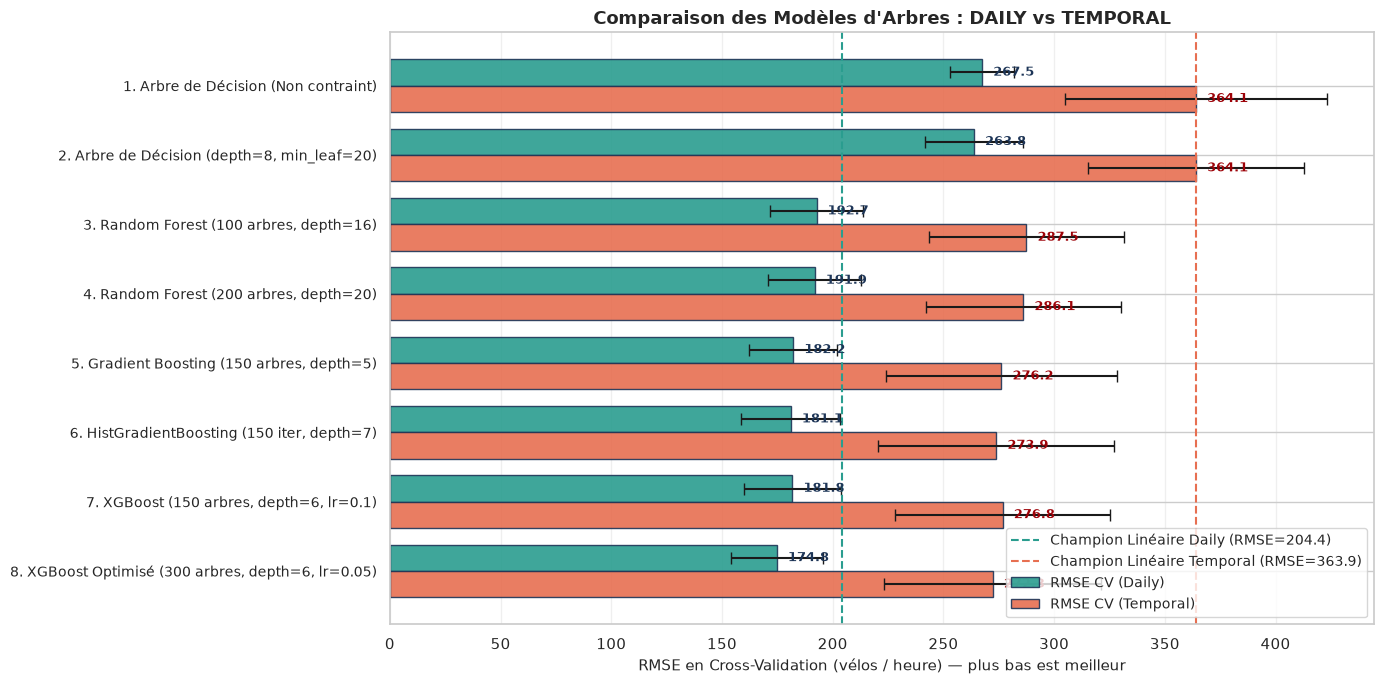

In [7]:
df_bilan = pd.DataFrame(resultats).set_index("Modèle").round({
    "RMSE CV (Daily)": 1, "R² CV (Daily)": 3, "Écart-type CV (Daily)": 1,
    "RMSE CV (Temporal)": 1, "R² CV (Temporal)": 3, "Écart-type CV (Temporal)": 1
})
display(df_bilan)

# Visualisation comparative de la RMSE CV : DAILY vs TEMPORAL
fig, ax = plt.subplots(figsize=(14, 7))
y_pos = np.arange(len(df_bilan))
height = 0.38

bars_d = ax.barh(y_pos - height/2, df_bilan["RMSE CV (Daily)"], height=height, xerr=df_bilan["Écart-type CV (Daily)"],
                 capsize=4, label="RMSE CV (Daily)", color="#2a9d8f", alpha=0.9, edgecolor="#1d3557")

bars_t = ax.barh(y_pos + height/2, df_bilan["RMSE CV (Temporal)"], height=height, xerr=df_bilan["Écart-type CV (Temporal)"],
                 capsize=4, label="RMSE CV (Temporal)", color="#e76f51", alpha=0.9, edgecolor="#1d3557")

ax.set_yticks(y_pos)
ax.set_yticklabels(df_bilan.index, fontsize=10)
ax.invert_yaxis()
ax.set_xlabel("RMSE en Cross-Validation (vélos / heure) — plus bas est meilleur", fontsize=11)
ax.set_title("Comparaison des Modèles d'Arbres : DAILY vs TEMPORAL", fontsize=13, fontweight="bold")

# Lignes de repère des modèles linéaires
ax.axvline(204.4, color="#2a9d8f", linestyle="--", linewidth=1.5, label="Champion Linéaire Daily (RMSE=204.4)")
ax.axvline(363.9, color="#e76f51", linestyle="--", linewidth=1.5, label="Champion Linéaire Temporal (RMSE=363.9)")

# Valeurs sur les barres
for bar in bars_d:
    w = bar.get_width()
    ax.text(w + 5, bar.get_y() + bar.get_height()/2, f"{w:.1f}", ha="left", va="center", fontsize=9, color="#1d3557", fontweight="bold")
for bar in bars_t:
    w = bar.get_width()
    ax.text(w + 5, bar.get_y() + bar.get_height()/2, f"{w:.1f}", ha="left", va="center", fontsize=9, color="#9d0208", fontweight="bold")

ax.legend(loc="lower right", fontsize=10)
ax.grid(True, alpha=0.3, axis="x")
plt.tight_layout()
plt.show()


## 9. Importance des Caractéristiques (*Feature Importances*) — DAILY vs TEMPORAL

Quelles sont les variables qui pilotent réellement la demande de vélos à Séoul ?
Comparons l'importance des variables selon la **Random Forest** (MDI - réduction moyenne d'impureté) et selon **XGBoost** (Gain total apporté par chaque division), sous les **deux protocoles** :
- **Ligne 1 : Protocole DAILY (283 jours)** : échantillonnage stratifié couvrant les 12 mois de l'année (vision globale des 4 saisons).
- **Ligne 2 : Protocole TEMPORAL (282 jours)** : entraînement du 01/12/2017 au 10/09/2018 (seulement 10 jours d'automne dans le train).


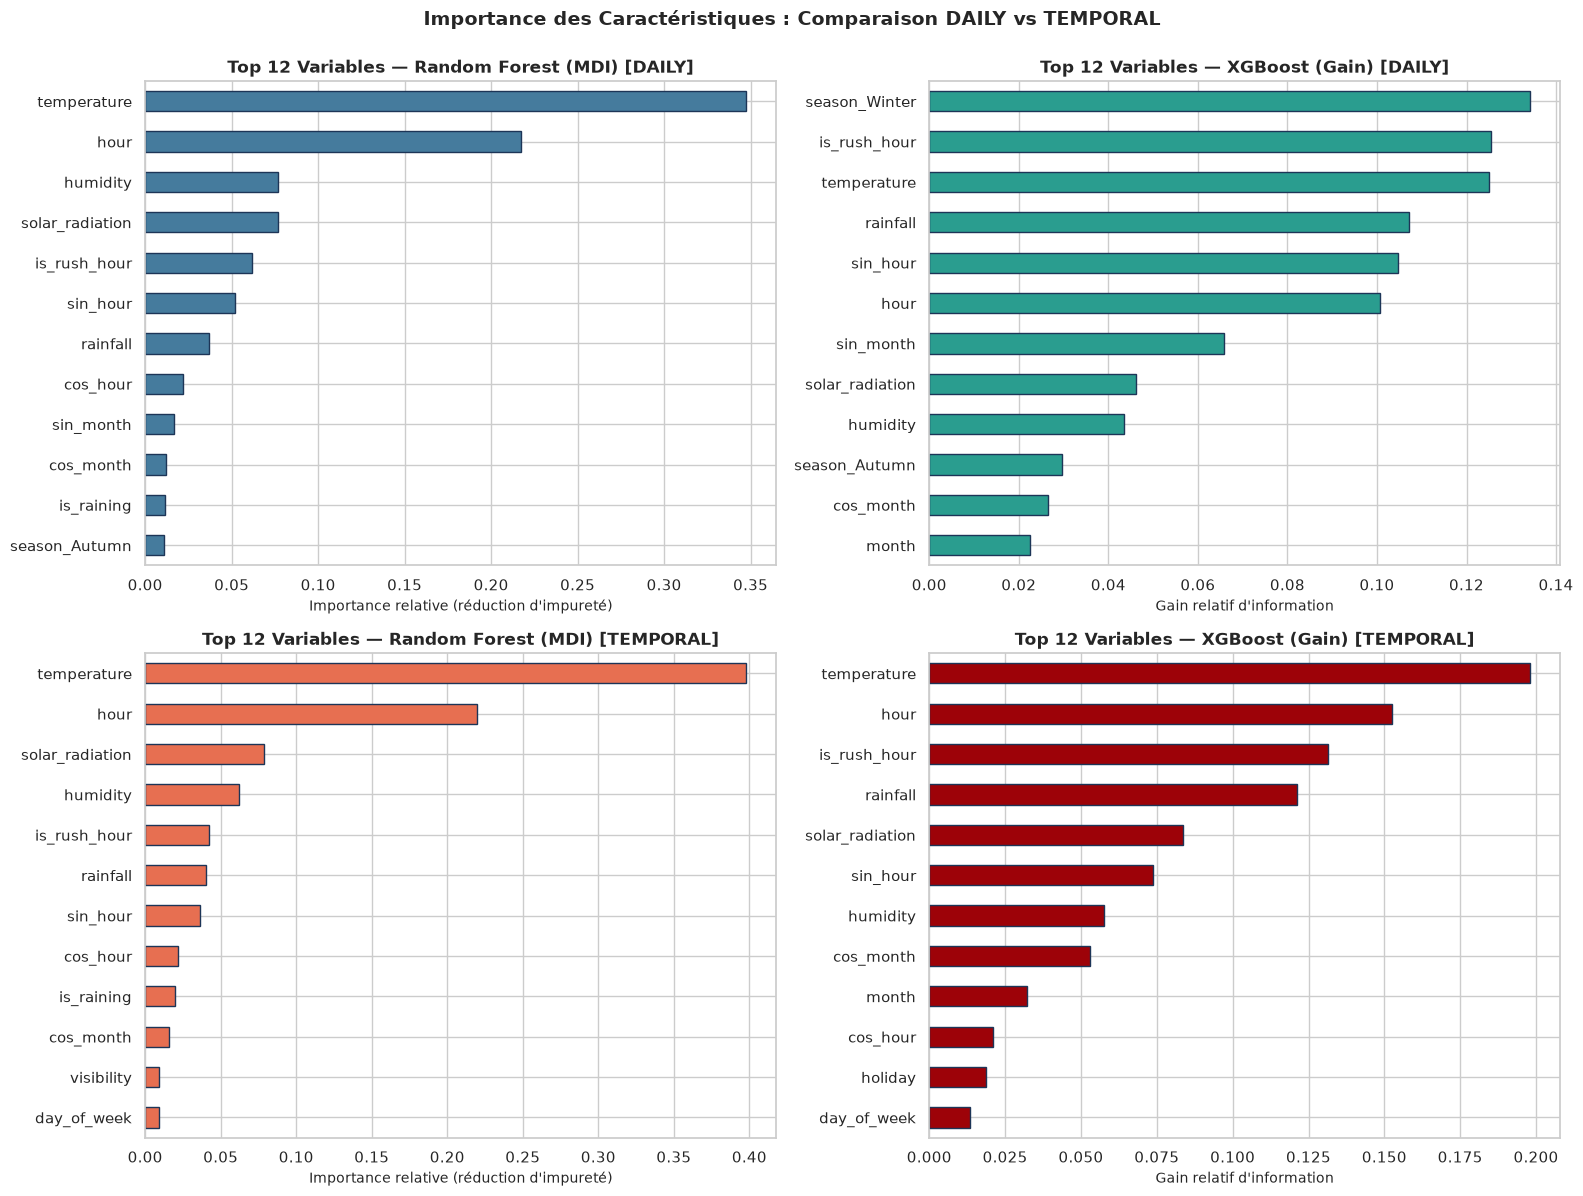

Top 3 DAILY    : ['temperature', 'hour', 'humidity']
Top 3 TEMPORAL : ['temperature', 'hour', 'solar_radiation']


In [8]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ==========================================
# 1. PROTOCOLE DAILY (283 jours, cycle annuel complet)
# ==========================================
# 1.1 Random Forest DAILY (MDI)
best_rf_daily = RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1)
best_rf_daily.fit(X_train, y_train)
imp_rf_daily = pd.Series(best_rf_daily.feature_importances_, index=FEATURES).sort_values(ascending=True)
imp_rf_daily.tail(12).plot(kind="barh", ax=axes[0, 0], color="#457b9d", edgecolor="#1d3557")
axes[0, 0].set_title("Top 12 Variables — Random Forest (MDI) [DAILY]", fontsize=12, fontweight="bold")
axes[0, 0].set_xlabel("Importance relative (réduction d'impureté)", fontsize=10)

# 1.2 XGBoost DAILY (Gain relatif)
if HAS_XGB:
    best_xgb_daily = xgb.XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1)
    best_xgb_daily.fit(X_train, y_train)
    imp_xgb_daily = pd.Series(best_xgb_daily.feature_importances_, index=FEATURES).sort_values(ascending=True)
    imp_xgb_daily.tail(12).plot(kind="barh", ax=axes[0, 1], color="#2a9d8f", edgecolor="#1d3557")
    axes[0, 1].set_title("Top 12 Variables — XGBoost (Gain) [DAILY]", fontsize=12, fontweight="bold")
    axes[0, 1].set_xlabel("Gain relatif d'information", fontsize=10)

# ==========================================
# 2. PROTOCOLE TEMPORAL (282 jours, du 01/12/2017 au 10/09/2018)
# ==========================================
# 2.1 Random Forest TEMPORAL (MDI)
best_rf_temporal = RandomForestRegressor(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1)
best_rf_temporal.fit(X_train_temporal, y_train_temporal)
imp_rf_temporal = pd.Series(best_rf_temporal.feature_importances_, index=FEATURES).sort_values(ascending=True)
imp_rf_temporal.tail(12).plot(kind="barh", ax=axes[1, 0], color="#e76f51", edgecolor="#1d3557")
axes[1, 0].set_title("Top 12 Variables — Random Forest (MDI) [TEMPORAL]", fontsize=12, fontweight="bold")
axes[1, 0].set_xlabel("Importance relative (réduction d'impureté)", fontsize=10)

# 2.2 XGBoost TEMPORAL (Gain relatif)
if HAS_XGB:
    best_xgb_temporal = xgb.XGBRegressor(n_estimators=200, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1)
    best_xgb_temporal.fit(X_train_temporal, y_train_temporal)
    imp_xgb_temporal = pd.Series(best_xgb_temporal.feature_importances_, index=FEATURES).sort_values(ascending=True)
    imp_xgb_temporal.tail(12).plot(kind="barh", ax=axes[1, 1], color="#9d0208", edgecolor="#1d3557")
    axes[1, 1].set_title("Top 12 Variables — XGBoost (Gain) [TEMPORAL]", fontsize=12, fontweight="bold")
    axes[1, 1].set_xlabel("Gain relatif d'information", fontsize=10)

plt.suptitle("Importance des Caractéristiques : Comparaison DAILY vs TEMPORAL", fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()

top3_d = imp_rf_daily.tail(3).index.tolist()[::-1]
top3_t = imp_rf_temporal.tail(3).index.tolist()[::-1]
print(f"Top 3 DAILY    : {top3_d}")
print(f"Top 3 TEMPORAL : {top3_t}")


## 10. Évaluation Finale sur les Jeux de Test (DAILY et TEMPORAL Walk-Forward)

Conformément à la rigueur méthodologique exigée en Machine Learning :
1. Les jeux de test (70 jours isolés en Daily, et 10 semaines consécutives en Temporal) sont restés **totalement intouchés** pendant tous les choix de modèles et réglages d'hyperparamètres.
2. Nous entraînons maintenant notre **modèle champion (XGBoost Optimisé)** :
   - Sur **l'intégralité du train Daily (283 jours)** pour évaluer les 70 jours de test d'interpolation.
   - Selon le **protocole Walk-Forward hebdomadaire** pour évaluer les 10 semaines de test d'extrapolation séquentielle.
3. Nous mesurons les métriques réelles de généralisation (RMSE, MAE, $R^2$) sur les deux cas d'usage réels.


In [9]:
# Modèle Champion des Arbres : XGBoost Optimisé
modele_champion = xgb.XGBRegressor(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    n_jobs=-1
)

# 1. Évaluation TEST - Protocole DAILY (70 jours isolés)
modele_champion.fit(X_train, y_train)
pred_test_daily = np.clip(modele_champion.predict(X_test), 0, None)
pred_test = pred_test_daily  # alias pour compatibilité

test_rmse = root_mean_squared_error(y_test, pred_test_daily)
test_mae = mean_absolute_error(y_test, pred_test_daily)
test_r2 = r2_score(y_test, pred_test_daily)

# 2. Évaluation TEST - Protocole TEMPORAL (Walk-Forward officiel 10 semaines)
preds_wf, reels_wf = [], []
for past, week in walk_forward(train_temporal, test_temporal):
    m_wf = xgb.XGBRegressor(
        n_estimators=300, max_depth=6, learning_rate=0.05, subsample=0.8,
        colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0, random_state=42, n_jobs=-1
    )
    m_wf.fit(past[FEATURES], past[TARGET])
    preds_wf.extend(np.clip(m_wf.predict(week[FEATURES]), 0, None))
    reels_wf.extend(week[TARGET])

preds_wf = np.array(preds_wf)
reels_wf = np.array(reels_wf)

test_rmse_wf = root_mean_squared_error(reels_wf, preds_wf)
test_mae_wf = mean_absolute_error(reels_wf, preds_wf)
test_r2_wf = r2_score(reels_wf, preds_wf)

# Tableau de synthèse des tests du Champion Arbre
df_test_champion = pd.DataFrame([
    {"Protocole": "DAILY (70 jours)", "Modèle": "XGBoost Optimisé",
     "RMSE": test_rmse, "MAE": test_mae, "R²": test_r2},
    {"Protocole": "TEMPORAL (Walk-Forward 10 sem)", "Modèle": "XGBoost Optimisé",
     "RMSE": test_rmse_wf, "MAE": test_mae_wf, "R²": test_r2_wf},
]).set_index(["Protocole", "Modèle"])

display(df_test_champion.round({"RMSE": 1, "MAE": 1, "R²": 3}))


,,RMSE,MAE,R²
Protocole,Modèle,,,
DAILY (70 jours),XGBoost Optimisé,178.1,104.9,0.921
TEMPORAL (Walk-Forward 10 sem),XGBoost Optimisé,226.4,143.3,0.857


### Analyse Graphique des Résidus du Champion XGBoost (DAILY vs TEMPORAL Walk-Forward)
Vérifions visuellement la qualité des prédictions sur les deux protocoles de test :
1. Alignement le long de la diagonale idéale ($y = \hat{y}$).
2. Symétrie et centrage de la distribution des erreurs résiduelles ($y - \hat{y}$).


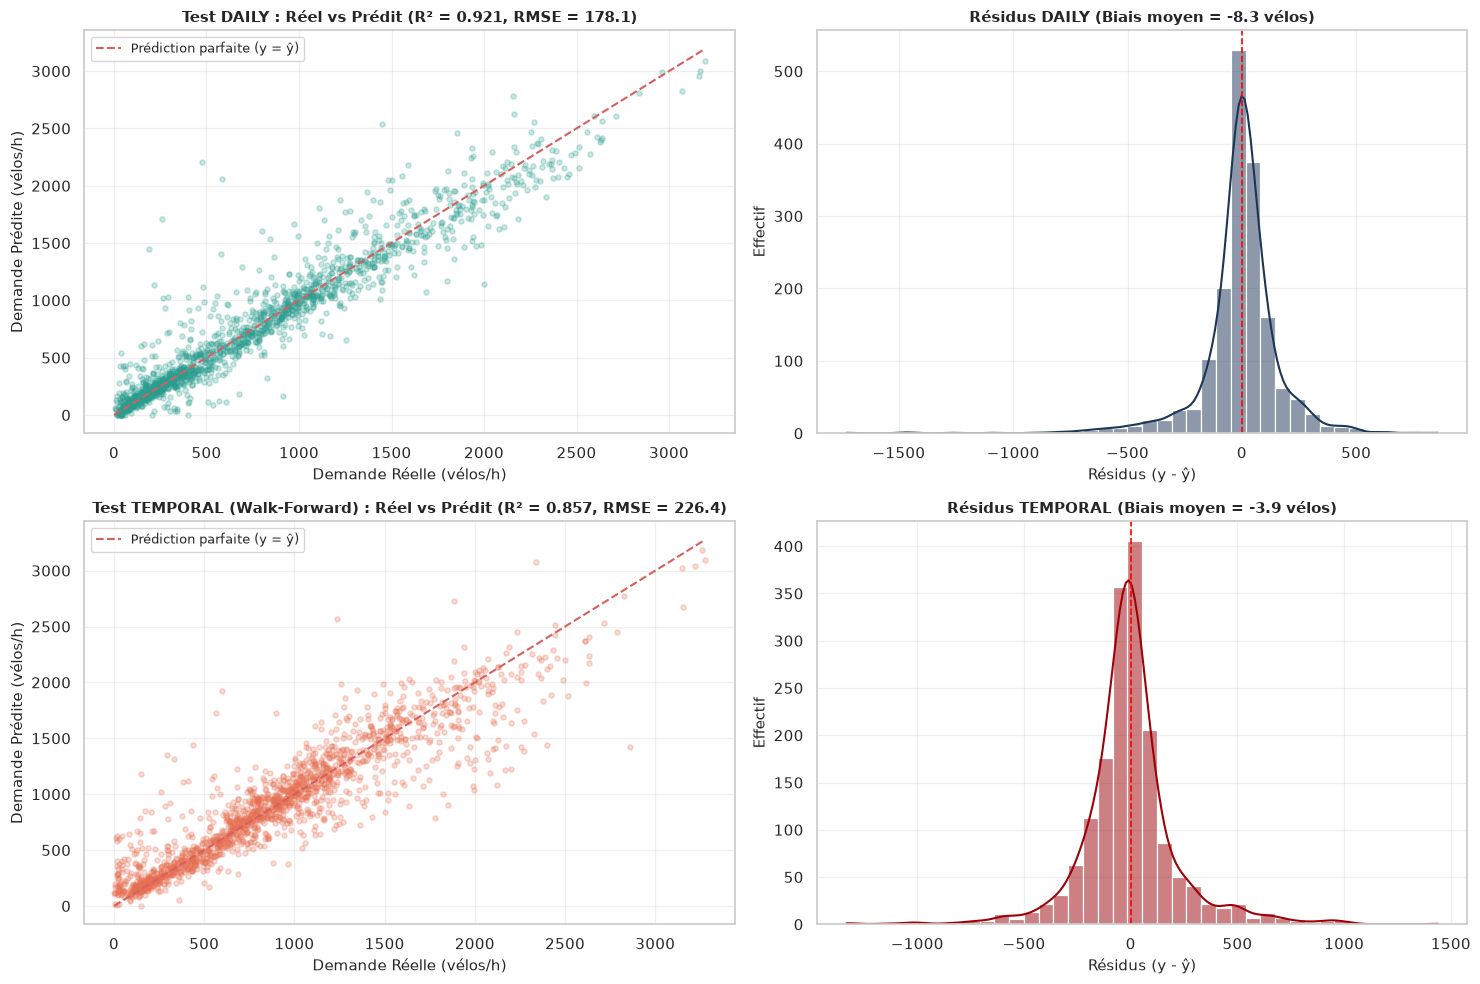

In [10]:
residuals_daily = y_test - pred_test_daily
residuals_wf = reels_wf - preds_wf

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Nuage de points DAILY : Réel vs Prédit
axes[0, 0].scatter(y_test, pred_test_daily, alpha=0.25, color="#2a9d8f", s=14)
max_d = max(y_test.max(), pred_test_daily.max())
axes[0, 0].plot([0, max_d], [0, max_d], "r--", linewidth=1.5, label="Prédiction parfaite (y = ŷ)")
axes[0, 0].set_xlabel("Demande Réelle (vélos/h)", fontsize=11)
axes[0, 0].set_ylabel("Demande Prédite (vélos/h)", fontsize=11)
axes[0, 0].set_title(f"Test DAILY : Réel vs Prédit (R² = {test_r2:.3f}, RMSE = {test_rmse:.1f})", fontsize=11, fontweight="bold")
axes[0, 0].legend(fontsize=9)
axes[0, 0].grid(True, alpha=0.3)

# 2. Distribution des résidus DAILY
sns.histplot(residuals_daily, kde=True, ax=axes[0, 1], color="#1d3557", bins=40)
axes[0, 1].axvline(0, color="red", linestyle="--", linewidth=1.2)
axes[0, 1].set_xlabel("Résidus (y - ŷ)", fontsize=11)
axes[0, 1].set_ylabel("Effectif", fontsize=11)
axes[0, 1].set_title(f"Résidus DAILY (Biais moyen = {residuals_daily.mean():.1f} vélos)", fontsize=11, fontweight="bold")
axes[0, 1].grid(True, alpha=0.3)

# 3. Nuage de points TEMPORAL Walk-Forward : Réel vs Prédit
axes[1, 0].scatter(reels_wf, preds_wf, alpha=0.25, color="#e76f51", s=14)
max_t = max(reels_wf.max(), preds_wf.max())
axes[1, 0].plot([0, max_t], [0, max_t], "r--", linewidth=1.5, label="Prédiction parfaite (y = ŷ)")
axes[1, 0].set_xlabel("Demande Réelle (vélos/h)", fontsize=11)
axes[1, 0].set_ylabel("Demande Prédite (vélos/h)", fontsize=11)
axes[1, 0].set_title(f"Test TEMPORAL (Walk-Forward) : Réel vs Prédit (R² = {test_r2_wf:.3f}, RMSE = {test_rmse_wf:.1f})", fontsize=11, fontweight="bold")
axes[1, 0].legend(fontsize=9)
axes[1, 0].grid(True, alpha=0.3)

# 4. Distribution des résidus TEMPORAL Walk-Forward
sns.histplot(residuals_wf, kde=True, ax=axes[1, 1], color="#9d0208", bins=40)
axes[1, 1].axvline(0, color="red", linestyle="--", linewidth=1.2)
axes[1, 1].set_xlabel("Résidus (y - ŷ)", fontsize=11)
axes[1, 1].set_ylabel("Effectif", fontsize=11)
axes[1, 1].set_title(f"Résidus TEMPORAL (Biais moyen = {residuals_wf.mean():.1f} vélos)", fontsize=11, fontweight="bold")
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


## 11. Bilan : modèles linéaires et modèles d'arbres

RMSE en vélos/h. Le test n'a été calculé que pour le modèle final de chaque famille.

| Famille | Modèle | CV daily | CV temporal | Test daily | Test temporal (walk-forward) |
|---|---|---|---|---|---|
| Linéaire | Polynôme d2 + FE + Ridge (`regression_lineaire.ipynb`) | 204.4 | 363.9 | 203.9 | 241.8 |
| Arbre simple | DecisionTree (profondeur 8) | 263.8 | 364.1 | — | — |
| Bagging | Random Forest (200 arbres) | 191.9 | 286.1 | — | — |
| Boosting | HistGradientBoosting | 181.1 | 273.9 | — | — |
| Boosting | **XGBoost optimisé** | **174.8** | **272.3** | **178.1** | **226.4** |

---

### Conclusion

1. **En daily**, XGBoost est le meilleur modèle d'arbres. Sur le test, il fait mieux que le meilleur modèle linéaire d'environ **26 vélos/h** (RMSE 178.1 contre 203.9), en apprenant directement les seuils et les interactions, sans créer 4 000 variables.
2. **En temporal**, XGBoost reste meilleur que le linéaire (226.4 contre 241.8 sur le test walk-forward), mais son erreur augmente davantage par rapport au daily (+27 % contre +19 %) : un arbre ne peut pas extrapoler au-delà des situations vues à l'entraînement. Le réentraînement hebdomadaire limite cette perte ($R^2 = 0.857$).

Les hyperparamètres de XGBoost sont réglés plus finement dans `tuning_xgboost.ipynb`, et tous les modèles sont comparés dans `comparaison_finale.ipynb`.

## 12. Chronique Temporelle : Ground Truth vs Prédiction (Courbes Heure par Heure sur le Jeu de Test)

Pour apprécier concrètement la qualité de notre modèle champion **XGBoost** au-delà des métriques scalaires globales (RMSE, MAE, $R^2$), nous traçons ci-dessous l'évolution heure par heure de la **demande réelle (*Ground Truth*)** face à la **demande prédite par XGBoost** sur 3 périodes contrastées de 168 heures (7 jours de test chacune ; en daily, ce sont des jours de test tirés au hasard, donc pas forcément consécutifs) :
1. **Période 1 : Test DAILY — Printemps / Été (Forte affluence)** : températures douces/chaudes, pics culminant à plus de 2 000 vélos/h.
2. **Période 2 : Test DAILY — Hiver (Climat rigoureux)** : gel et froid réduisant l'usage du vélo.
3. **Période 3 : Test TEMPORAL (Walk-Forward) — Semaine d'Automne Inconnue** : 7 jours consécutifs réels de la première semaine de test (septembre 2018), prévus en situation opérationnelle par réentraînement hebdomadaire.


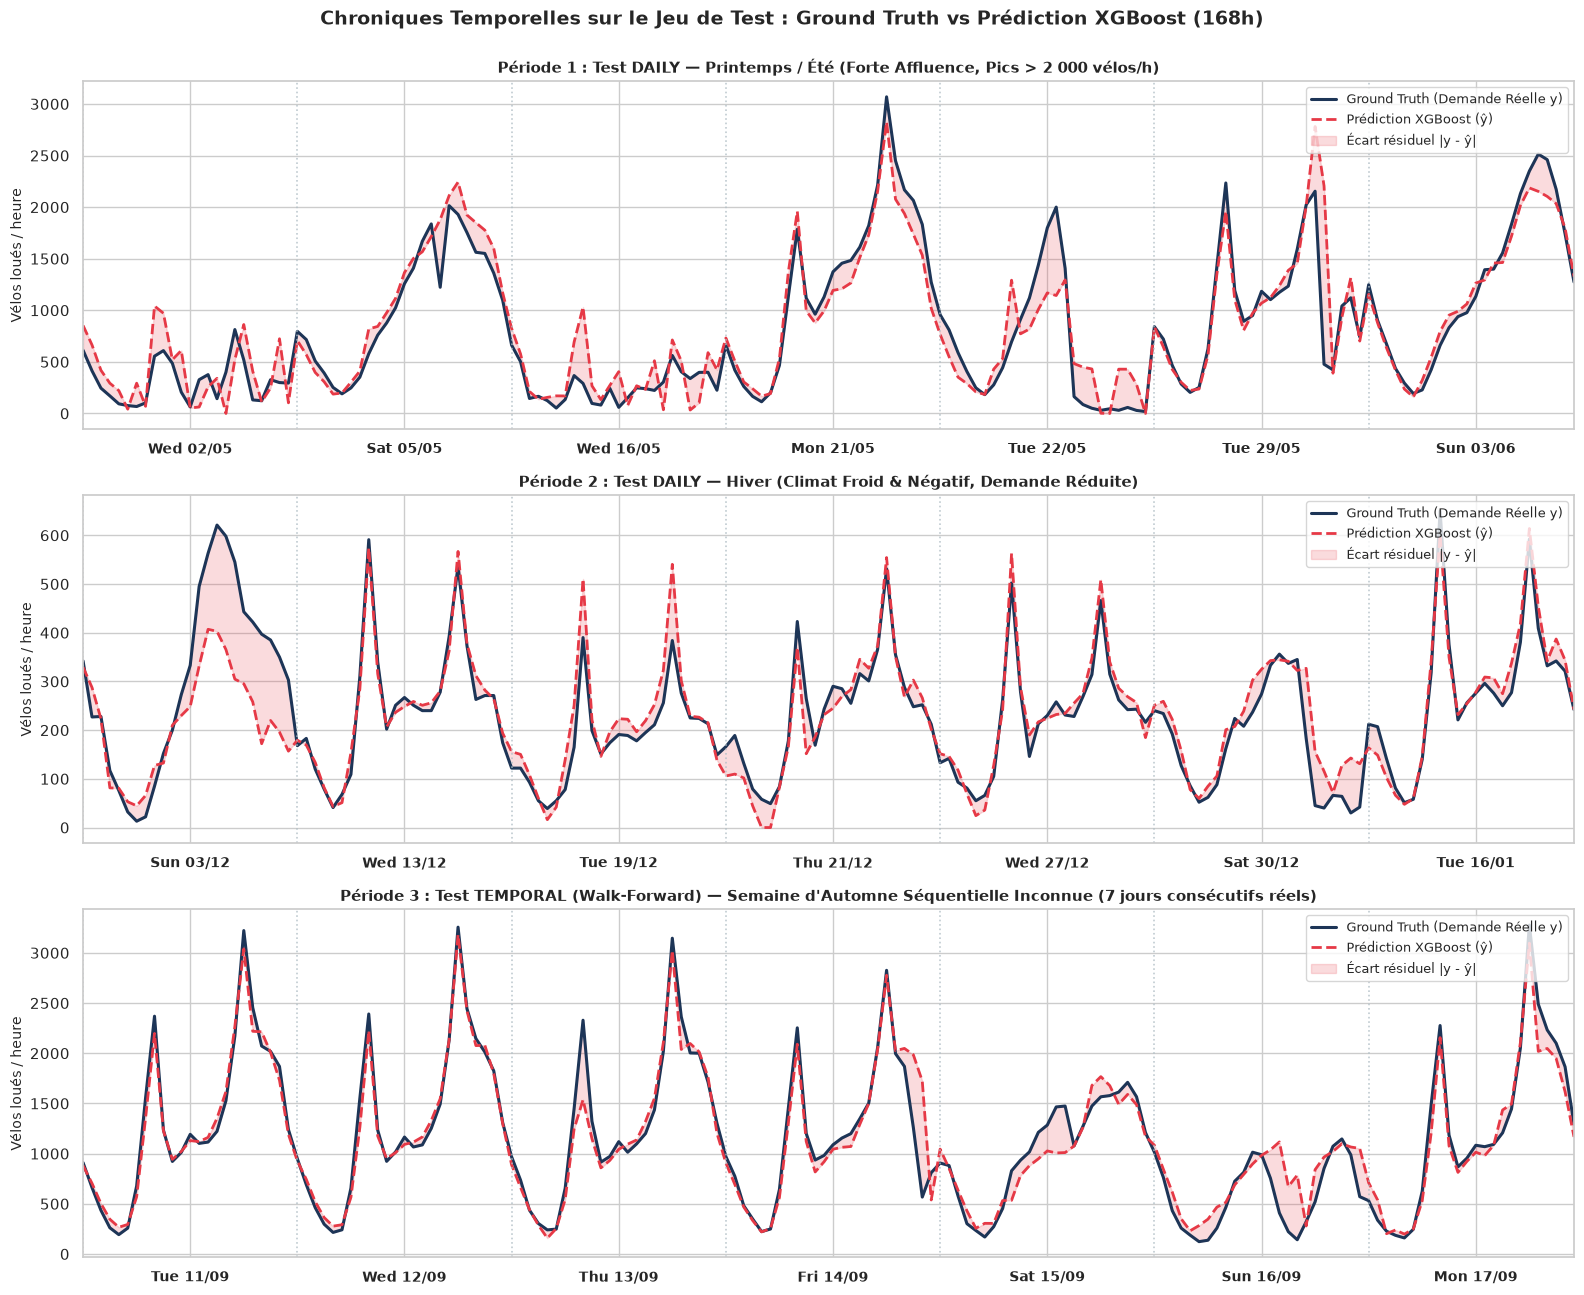

In [11]:
test_with_pred = test[["date", "hour", CIBLE]].copy()
test_with_pred["prediction"] = pred_test_daily
test_with_pred["month"] = test_with_pred["date"].dt.month
test_with_pred = test_with_pred.sort_values(by=["date", "hour"]).reset_index(drop=True)

# 1. Échantillon Printemps/Été DAILY (mai-juin) : 168 heures
sample_summer = test_with_pred[test_with_pred["month"].isin([5, 6])].iloc[:168].reset_index(drop=True)

# 2. Échantillon Hiver DAILY (décembre-janvier) : 168 heures
sample_winter = test_with_pred[test_with_pred["month"].isin([12, 1])].iloc[:168].reset_index(drop=True)

# 3. Échantillon Automne TEMPORAL Walk-Forward (septembre) : 168 heures réelles consécutives
sample_wf = test_temporal.iloc[:168].copy().reset_index(drop=True)
sample_wf["prediction"] = preds_wf[:168]

fig, axes = plt.subplots(3, 1, figsize=(16, 13))

for ax, sample, title in [
    (axes[0], sample_summer, "Période 1 : Test DAILY — Printemps / Été (Forte Affluence, Pics > 2 000 vélos/h)"),
    (axes[1], sample_winter, "Période 2 : Test DAILY — Hiver (Climat Froid & Négatif, Demande Réduite)"),
    (axes[2], sample_wf, "Période 3 : Test TEMPORAL (Walk-Forward) — Semaine d'Automne Séquentielle Inconnue (7 jours consécutifs réels)")
]:
    x_idx = np.arange(len(sample))
    ax.plot(x_idx, sample[CIBLE], label="Ground Truth (Demande Réelle y)", color="#1d3557", linewidth=2.2)
    ax.plot(x_idx, sample["prediction"], label="Prédiction XGBoost (ŷ)", color="#e63946", linestyle="--", linewidth=2.0)
    ax.fill_between(x_idx, sample[CIBLE], sample["prediction"], color="#e63946", alpha=0.18, label="Écart résiduel |y - ŷ|")
    
    # Repères visuels pour chaque jour à minuit
    day_starts = range(0, len(sample), 24)
    day_labels = [sample["date"].iloc[i].strftime("%a %d/%m") for i in day_starts]
    ax.set_xticks(ticks=[i + 12 for i in day_starts])
    ax.set_xticklabels(day_labels, fontsize=10, fontweight="bold")
    
    for ds in day_starts:
        ax.axvline(ds, color="#b0bec5", linestyle=":", alpha=0.8, linewidth=1.2)
        
    ax.set_ylabel("Vélos loués / heure", fontsize=10)
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.legend(loc="upper right", fontsize=9, frameon=True)
    ax.set_xlim(0, len(sample) - 1)

plt.suptitle("Chroniques Temporelles sur le Jeu de Test : Ground Truth vs Prédiction XGBoost (168h)", fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout()
plt.show()
